# 23. 상대적 유지 순위모형: 로그 연면적 포함5변수·개통 전10명 이상

사용자 지정 기준으로 원래126개 중 기초10명 미만24개를 제외한102개(운정49/킨텍스25/대곡28)에서 **학습·검증 모두** 다시 수행한다.

입력은 개통 전 권역 내 비중(%), log(1+개통 전 승차인원), 보행시간 원 단위(분), 경쟁 목적지 비율(%), log(1+연면적[천㎡])의5개다.

- **정답과 입력 비중의 분모는 원래126개 기준 유지**. 제외 후 권역 변화율을 다시 계산해 정답을 바꾸지 않는다.
- 같은 역의 상대적 유지/비유지 격자 쌍으로 L2 쌍대 로지스틱 학습. 두 역 학습/한 역 외부검증, 학습역 내부 LOSO에서 C 선택·전처리 적합.
- 전체5변수 모형도 같은102개에 제한하고 해당 권역 안에서 순위를 다시 매겨 비교한다. ‘기존 상위27개 중10명 이상만 남긴 결과’와 다르다.
- 비교하는 두 경우는 같은 정답·같은 평가격자·같은 상위수21개다. 126개 평가의 AUC와102개 평가의 AUC를 직접 차감해 학습 효과로 해석하지 않는다.
- C의 기초10명 미만은 판단 유보/별도검토 대상이며 예측값0을 넣지 않는다. 이번 결과로 기준을 다시 바꾸지 않는다.
- 기존 모형/OLS를 수정하지 않는다. CSV·모델·그림 파일 자동 저장 없음. GTX-C 실제 적용/독립검증이 아니다.

In [1]:
# 프로젝트 루트(UROP) 자동 탐색 — 절대경로 없이 어느 컴퓨터에서도 동작
import sys
from pathlib import Path
UROP_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'config.py').is_file() and (p / 'code').is_dir())
for _d in [UROP_ROOT, *sorted(d for d in (UROP_ROOT / 'code').rglob('*') if d.is_dir() and d.name != '__pycache__')]:
    if str(_d) not in sys.path:
        sys.path.append(str(_d))

from pathlib import Path
import importlib.util
import pandas as pd, matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display
paths=[*sorted(d for d in (UROP_ROOT / 'code').rglob('*') if d.is_dir()), Path.cwd(),Path.cwd()/'analysis',Path.cwd()/'gtx_a_bus_analysis'/'analysis',Path.cwd()/'github_2026-UROP'/'gtx_a_bus_analysis'/'analysis']
ANALYSIS=next((p for p in paths if (p/'23_쌍대순위_5변수_10명이상.py').exists()),None)
if ANALYSIS is None:raise FileNotFoundError('프로젝트 또는 analysis 폴더에서 실행하세요.')
spec=importlib.util.spec_from_file_location('pairwise_ge10',next((UROP_ROOT / 'code').rglob('23_쌍대순위_5변수_10명이상.py')))
experiment=importlib.util.module_from_spec(spec);spec.loader.exec_module(experiment)
fonts={f.name for f in font_manager.fontManager.ttflist}
font=next((f for f in ['AppleGothic','Apple SD Gothic Neo','NanumGothic','Malgun Gothic','Noto Sans CJK KR'] if f in fonts),None)
if font:plt.rcParams['font.family']=font
plt.rcParams.update({'axes.unicode_minus':False,'figure.dpi':110,'font.size':11})
pd.set_option('display.max_columns',25)
oof,rows,overall,tops,settings,coverage,coefs,old_overall=experiment.evaluate()
display(coverage.round(4));display(settings.round(4))
display(overall.round(4));display(rows.round(4))

,권역,원래n,10명이상n,제외n,유지된개통전승차비율,고정권역변화율
0,운정중앙,63,49,14,0.9897,-70.5592
1,킨텍스,26,25,1,0.9990,-69.7301
2,대곡,37,28,9,0.9863,-61.2510


,검증역,학습n,검증n,학습양방향쌍수,선택C,내부역평균AUC
0,운정중앙,53,49,702,0.0316,0.5942
1,킨텍스,77,25,1578,0.0316,0.7163
2,대곡,74,28,1500,10.0000,0.6945


,모형,평가n,역평균AUC,격자수가중AUC,전체쌍Loss,상위수,적중수,상위Precision,상위실제Y중앙값
0,전체학습_같은102개평가,102,0.7363,0.7449,0.5709,21,16,0.7619,9.4481
1,10명이상재학습,102,0.7298,0.7378,0.5680,21,15,0.7143,10.5592


,모형,검증역,n,AUC,PairwiseLoss,비교쌍수,권역상대유지비율,상위수,적중수,Precision20,Lift20,상위실제Y중앙값
0,전체학습_같은102개평가,대곡,28,0.7231,0.5372,195,0.4643,6,4,0.6667,1.4359,10.0325
1,전체학습_같은102개평가,운정중앙,49,0.7744,0.5659,594,0.4490,10,8,0.8000,1.7818,10.0037
2,전체학습_같은102개평가,킨텍스,25,0.7115,0.6319,156,0.5200,5,4,0.8000,1.5385,4.9414
3,10명이상재학습,운정중앙,49,0.7677,0.5587,594,0.4490,10,7,0.7000,1.5591,14.2434
4,10명이상재학습,킨텍스,25,0.7244,0.6093,156,0.5200,5,4,0.8000,1.5385,4.9414
5,10명이상재학습,대곡,28,0.6974,0.5630,195,0.4643,6,4,0.6667,1.4359,10.0325


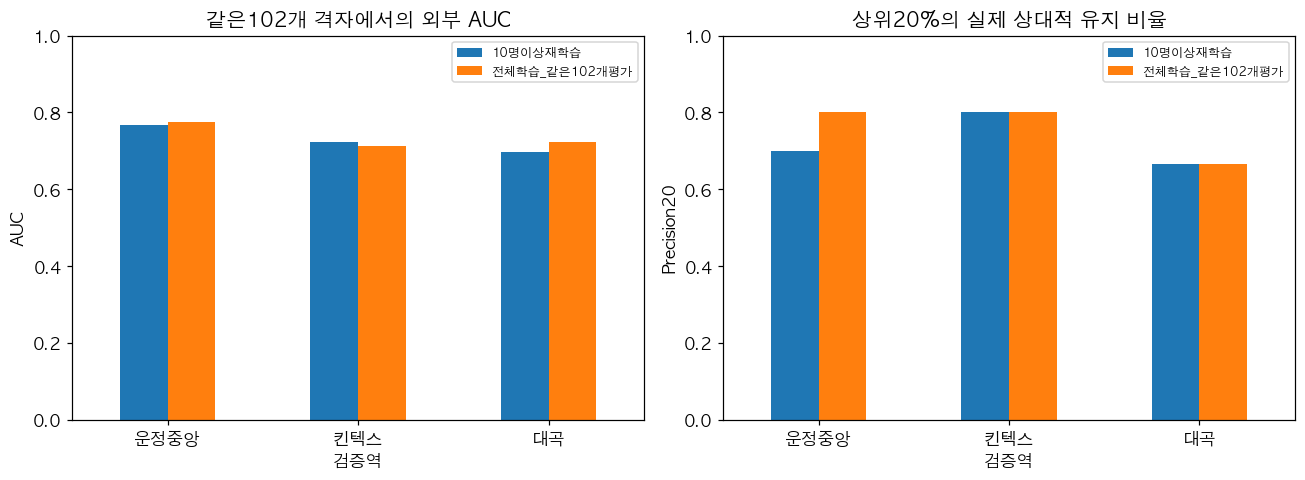

,모형,검증역,상위비율,K,적중수,Precision,Lift,실제Y중앙값
0,전체학습_같은102개평가,대곡,0.1,3,3,1.0000,2.1538,11.2510
1,전체학습_같은102개평가,대곡,0.2,6,4,0.6667,1.4359,10.0325
2,전체학습_같은102개평가,대곡,0.3,9,6,0.6667,1.4359,11.2510
3,전체학습_같은102개평가,운정중앙,0.1,5,4,0.8000,1.7818,10.5592
4,전체학습_같은102개평가,운정중앙,0.2,10,8,0.8000,1.7818,10.0037
5,전체학습_같은102개평가,운정중앙,0.3,15,11,0.7333,1.6333,9.4481
6,전체학습_같은102개평가,킨텍스,0.1,3,2,0.6667,1.2821,0.2829
7,전체학습_같은102개평가,킨텍스,0.2,5,4,0.8000,1.5385,4.9414
8,전체학습_같은102개평가,킨텍스,0.3,8,5,0.6250,1.2019,0.5237
9,10명이상재학습,운정중앙,0.1,5,3,0.6000,1.3364,3.8926


In [2]:
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for ax,metric,title in [(axes[0],'AUC','같은102개 격자에서의 외부 AUC'),(axes[1],'Precision20','상위20%의 실제 상대적 유지 비율')]:
 rows.pivot(index='검증역',columns='모형',values=metric).reindex(experiment.STATIONS).plot.bar(ax=ax)
 ax.set(xlabel='검증역',ylabel=metric,title=title,ylim=(0,1));ax.tick_params(axis='x',rotation=0);ax.legend(fontsize=8)
plt.tight_layout();plt.show()
display(tops.round(4))

## 10명 이상 재학습 모형의 상위21개

Y=실제 격자 변화율−원래 권역 전체 변화율. 양수는 권역보다 잘 유지(증가 포함)됐다는 뜻이다. 점수는 예측 변화율이나 확률이 아니며 Y의 크기를 정렬하도록 학습한 것도 아니다.

In [3]:
selected=oof[oof['상위20']].sort_values(['nearest_station','순위'])
with pd.option_context('display.max_rows',30):
 display(selected[['nearest_station','셀 ID','순위','board_2024_all','board_2025_all','R_s','R_i','Y','점수']].round(3))
print('상위수:',len(selected),'| Y>0:',int((selected.Y>0).sum()),'| 실제Y중앙값:',round(selected.Y.median(),3),'%p')

상위수: 21 | Y>0: 15 | 실제Y중앙값: 10.559 %p


,nearest_station,셀 ID,순위,board_2024_all,board_2025_all,R_s,R_i,Y,점수
74,대곡,14284,1,12.0,6.0,-61.251,-50.000,11.251,-0.362
75,대곡,7608,2,11.0,6.0,-61.251,-45.455,15.796,-0.759
76,대곡,12461,3,595.0,283.0,-61.251,-52.437,8.814,-0.894
77,대곡,12985,4,10.0,5.0,-61.251,-50.000,11.251,-1.318
78,대곡,10471,5,16.0,1.0,-61.251,-93.750,-32.499,-1.503
79,대곡,10682,6,25.0,5.0,-61.251,-80.000,-18.749,-1.550
0,운정중앙,4714,1,12.0,2.0,-70.559,-83.333,-12.774,-0.172
1,운정중앙,76,2,17.0,15.0,-70.559,-11.765,58.795,-0.181
2,운정중앙,12466,3,24.0,5.0,-70.559,-79.167,-8.607,-0.245
3,운정중앙,12334,4,12.0,4.0,-70.559,-66.667,3.893,-0.260


## 이번 결과

| 검증역 | n | AUC | 상위20% 실제 상대적 유지 | Precision | Lift | 상위 실제Y 중앙값 |
|---|---:|---:|---:|---:|---:|---:|
| 운정중앙 |49|.768|7/10|70.0%|1.56|+14.24%p|
| 킨텍스 |25|.724|4/5|80.0%|1.54|+4.94%p|
| 대곡 |28|.697|4/6|66.7%|1.44|+10.03%p|

역평균 AUC=.7298, 전체 상위21개 중15개(71.4%) 실제 상대적 유지, 상위 실제Y 중앙값+10.56%p다.

공통102개에서 전체학습 모형은 AUC=.7363, 상위16/21(76.2%), 손실=.5709였고,10명 이상 재학습 모형은 AUC=.7298, 상위15/21(71.4%), 손실=.5680이었다. 학습자료의 작은 격자를 제외했다고 성능이 개선됐다고 볼 결과는 아니다. 그러나1→4명 등의 극단적 격자 없이도 세 역 모두 AUC .697 이상과 Lift1 초과의 순위 신호는 남았다.

제외 조건은 표본 범위를 바꾸고 기초10명 이상에도 분모 불안정성이 완전히 사라지는 것은 아니다. 같은 자료의 반복 탐색과 독립역3개라는 한계가 남으며, 이 결과로 최종 일반화 성능을 확정하지 않는다.